In [1]:
import re
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)

BASE = Path(r"C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0")
DIRS = {"raw": BASE / "data" / "raw" / "hortikultura",
        "clean": BASE / "data" / "clean" / "hortikultura",
        "model_ready": BASE / "data" / "model_ready",
        "eda": BASE / "outputs" / "eda",
        "reports": BASE / "outputs" / "reports"}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

FILES = {
    ("buah", "produksi_kec"): "Produksi_Hortikultura_Buah_per_kecamatan.csv",
    ("buah", "luas_kec"):     "Luas_Panen_Hortikultura_Buah_per_kecamatan.csv",
    ("buah", "produksi_kab"): "Total_Produksi_Hortikultura_Buah.csv",
    ("buah", "luas_kab"):     "Luas_Panen_Hortikultura_Buah.csv",
    ("buah", "produktivitas_kec"): "Produktivitas_Hortikultura_Buah_per_kecamatan.csv",
    ("buah", "produktivitas_kab"): "Produktivitas_Hortikultura_Buah.csv",
    ("sayur", "produksi_kec"): "Produksi_Hortikultura_Sayur_per_kecamatan.csv",
    ("sayur", "luas_kec"):     "Luas_Panen_Hortikultura_Sayur_per_kecamatan.csv",
    ("sayur", "produksi_kab"): "Total_Produksi_Hortikultura_Sayur.csv",
    ("sayur", "luas_kab"):     "Luas_Panen_Hortikultura_Sayur.csv",
    ("sayur", "produktivitas_kec"): "Produktivitas_Hortikultura_Sayur_per_kecamatan.csv",
    ("sayur", "produktivitas_kab"): "Produktivitas_Hortikultura_Sayur_Kabupaten.csv",
}
missing = [f for f in FILES.values() if not (DIRS["raw"] / f).exists()]
print("File mentah:", len(FILES) - len(missing), "dari", len(FILES), "ditemukan", missing if missing else "")

File mentah: 12 dari 12 ditemukan 


In [2]:
def read_raw(key):
    df = pd.read_csv(DIRS["raw"] / FILES[key], encoding="utf-8-sig", dtype=str)
    df.columns = [re.sub(r"\s+", " ", c).strip() for c in df.columns]
    for c in df.columns:
        df[c] = df[c].str.replace(r"\s+", " ", regex=True).str.strip()
    return df

RAW = {k: read_raw(k) for k in FILES}

tokens = set()
for (kel, jenis), df in RAW.items():
    nilai = [c for c in df.columns if c.lower() not in ("tahun", "kecamatan", "jenis tanaman", "komoditas", "satuan_luas")]
    for c in nilai:
        v = df[c].dropna().unique()
        tokens |= {x for x in v if pd.isna(pd.to_numeric(x, errors="coerce"))}
print("Teks non-angka di kolom nilai:", sorted(tokens))

def to_num(s):
    return pd.to_numeric(s.replace({"-": np.nan, "": np.nan}), errors="coerce")

KOM = {kel: sorted(RAW[(kel, "produktivitas_kab")]["komoditas"].unique()) for kel in ["buah", "sayur"]}
KOM_BAKU = {k.casefold(): k for v in KOM.values() for k in v}
KELOMPOK_OF = {k: kel for kel, v in KOM.items() for k in v}
print({kel: len(v) for kel, v in KOM.items()}, "komoditas")

KEC_FIX = {"Kayenkidul": "Kayen Kidul"}

Teks non-angka di kolom nilai: ['-']
{'buah': 27, 'sayur': 26} komoditas


format panjang dan nama baku

In [3]:
def baku_komoditas(label):
    lab = label.casefold()
    cand = [b for b in KOM_BAKU if lab.startswith(b)]
    if not cand:
        raise ValueError(f"komoditas tidak dikenal: {label}")
    return KOM_BAKU[max(cand, key=len)]

def wide_kec(kel, jenis, awalan):
    df = RAW[(kel, jenis)].rename(columns={"Tahun": "tahun", "Kecamatan": "kecamatan"})
    long = df.melt(id_vars=["tahun", "kecamatan"], var_name="kolom", value_name="nilai")
    long["komoditas"] = (long["kolom"].str.replace(awalan, "", regex=True).str.replace(r"\s*\(.*$", "", regex=True)
                         .str.strip().map(baku_komoditas))
    long["nilai"] = to_num(long["nilai"]); long["tahun"] = long["tahun"].astype(int)
    long["kecamatan"] = long["kecamatan"].replace(KEC_FIX)
    return long.drop(columns="kolom")

def long_kab(kel, jenis):
    df = RAW[(kel, jenis)]; nilai = df.columns[2]
    return pd.DataFrame({"tahun": df["Tahun"].astype(int), "komoditas": df["Jenis Tanaman"].map(baku_komoditas), "nilai": to_num(df[nilai])})

parts_kec, parts_kab, rows_total = [], [], []
for kel in ["buah", "sayur"]:
    pr = wide_kec(kel, "produksi_kec", r"^Produksi\s+").rename(columns={"nilai": "produksi_kw"})
    lu = wide_kec(kel, "luas_kec", r"^Luas Panen\s+").rename(columns={"nilai": "luas"})
    m = pr.merge(lu, on=["tahun", "kecamatan", "komoditas"], how="outer", validate="1:1")
    m["kelompok"] = kel
    rows_total.append(m[m["kecamatan"] == "Kediri"])      # baris "Kediri" = total kabupaten, bukan kecamatan
    parts_kec.append(m[m["kecamatan"] != "Kediri"])
    kb = long_kab(kel, "produksi_kab").rename(columns={"nilai": "produksi_kw"}).merge(
         long_kab(kel, "luas_kab").rename(columns={"nilai": "luas"}), on=["tahun", "komoditas"], how="outer", validate="1:1")
    kb["kelompok"] = kel; parts_kab.append(kb)
kec_raw = pd.concat(parts_kec, ignore_index=True); kab_raw = pd.concat(parts_kab, ignore_index=True); tot_raw = pd.concat(rows_total, ignore_index=True)

print("kecamatan:", kec_raw["kecamatan"].nunique(), "| komoditas:", kec_raw["komoditas"].nunique(), "| tahun:", sorted(int(t) for t in kec_raw["tahun"].unique()))
print("kec_raw:", kec_raw.shape, "| kab_raw:", kab_raw.shape, "| baris total 'Kediri' dipisah:", tot_raw.shape)

kecamatan: 26 | komoditas: 53 | tahun: [2020, 2021, 2022, 2023, 2024, 2025]
kec_raw: (8268, 6) | kab_raw: (318, 5) | baris total 'Kediri' dipisah: (318, 6)


satuan dan produktivitas

In [4]:
UNIT_JAMUR = {"Jamur Tiram", "Jamur Merang", "Jamur Lainnya"}     # luas jamur dalam m2

def finalize(df):
    d = df.copy()
    d["produksi"] = d["produksi_kw"] * 100                       # kuintal -> kg
    d["unit_luas"] = np.where(d["komoditas"].isin(UNIT_JAMUR), "m2", "ha")
    for c in ["produksi", "luas"]:
        d.loc[d[c] <= 0, c] = np.nan                              # 0 dan "-" = tidak ada laporan
    ada = d["produksi"].notna() & d["luas"].notna()
    d["produktivitas"] = np.where(ada, d["produksi"] / d["luas"], np.nan)      # kg/ha atau kg/m2
    return d.drop(columns="produksi_kw")

kec = finalize(kec_raw); kab = finalize(kab_raw); tot = finalize(tot_raw)

inkonsisten = ((kec["produksi"].notna() ^ kec["luas"].notna()).sum(), (kab["produksi"].notna() ^ kab["luas"].notna()).sum())
print("Baris produksi/luas tidak berpasangan (kecamatan, kabupaten):", tuple(int(x) for x in inkonsisten))

Baris produksi/luas tidak berpasangan (kecamatan, kabupaten): (0, 0)


validasi silang

In [5]:
s = kec.groupby(["kelompok", "komoditas", "tahun"])[["produksi", "luas"]].sum(min_count=1)
cek = (s.join(tot.set_index(["kelompok", "komoditas", "tahun"])[["produksi", "luas"]], rsuffix="_total")
        .join(kab.set_index(["kelompok", "komoditas", "tahun"])[["produksi", "luas"]], rsuffix="_kab"))
for c in ["produksi", "luas"]:
    d1 = (cek[c] - cek[f"{c}_total"]).abs().max(); d2 = (cek[f"{c}_kab"] - cek[f"{c}_total"]).abs()
    print(f"{c:8s}| selisih maks jumlah-kecamatan vs baris Kediri: {d1:.4f} | file kabupaten vs baris Kediri: maks {d2.max():.4f}, berbeda di {(d2 > 1e-6).sum()} baris")

def prod_file(kel, level):
    p = RAW[(kel, f"produktivitas_{level}")].copy(); p["tahun"] = p["tahun"].astype(int)
    p["komoditas"] = p["komoditas"].map(baku_komoditas); p["p_file"] = to_num(p["produktivitas_kuintal_ha"]); p["kelompok"] = kel
    if "kecamatan" in p: p["kecamatan"] = p["kecamatan"].replace(KEC_FIX)
    return p
pk = pd.concat([prod_file(k, "kec") for k in ["buah", "sayur"]]); pb = pd.concat([prod_file(k, "kab") for k in ["buah", "sayur"]])
for nama, a, b, kunci in [("kecamatan", kec, pk, ["kelompok", "kecamatan", "komoditas", "tahun"]), ("kabupaten", kab, pb, ["kelompok", "komoditas", "tahun"])]:
    m = a[a["unit_luas"] == "ha"].merge(b[kunci + ["p_file"]], on=kunci, how="left")
    m["hitung_kw_ha"] = m["produktivitas"] / 100
    ok = m.dropna(subset=["hitung_kw_ha", "p_file"])
    print(f"{nama:9s}| dicocokkan {len(ok)} baris | selisih maks {np.abs(ok['hitung_kw_ha'] - ok['p_file']).max():.3f} kuintal/ha"
          f" | ada di file produktivitas tapi tidak terhitung: {(m['hitung_kw_ha'].isna() & m['p_file'].notna()).sum()}")

produksi| selisih maks jumlah-kecamatan vs baris Kediri: 0.0000 | file kabupaten vs baris Kediri: maks 0.0000, berbeda di 0 baris
luas    | selisih maks jumlah-kecamatan vs baris Kediri: 0.0000 | file kabupaten vs baris Kediri: maks 0.0000, berbeda di 0 baris
kecamatan| dicocokkan 3214 baris | selisih maks 0.005 kuintal/ha | ada di file produktivitas tapi tidak terhitung: 0
kabupaten| dicocokkan 277 baris | selisih maks 0.005 kuintal/ha | ada di file produktivitas tapi tidak terhitung: 0


kelengkapan tahun dan simpan data bersih

In [6]:
cov = kec.assign(isi=kec["produksi"].notna()).groupby(["kelompok", "tahun"])["isi"].mean().unstack("kelompok")
rasio = cov.apply(lambda c: pd.Series({t: c[t] / c.drop(t).median() for t in c.index}))
display(pd.concat({"porsi_terisi": cov, "rasio_vs_median": rasio}, axis=1).round(3))
TAHUN_LENGKAP_OVERRIDE = None                                  # isi list tahun bila mau menentukan sendiri
ok_years = [int(t) for t in rasio.index[(rasio >= 0.85).all(axis=1)]]
COMPLETE_YEARS = sorted(TAHUN_LENGKAP_OVERRIDE or ok_years)
for d in (kec, kab): d["tahun_lengkap"] = d["tahun"].isin(COMPLETE_YEARS)

cols = ["kelompok", "kecamatan", "komoditas", "tahun", "produksi", "luas", "unit_luas", "produktivitas", "tahun_lengkap"]
clean = kec[cols].sort_values(["kelompok", "kecamatan", "komoditas", "tahun"]).reset_index(drop=True)
kab = kab[[c for c in cols if c != "kecamatan"]].sort_values(["kelompok", "komoditas", "tahun"]).reset_index(drop=True)
clean.to_csv(DIRS["clean"] / "hortikultura_kecamatan_clean.csv", index=False, encoding="utf-8-sig")
kab.to_csv(DIRS["clean"] / "hortikultura_kabupaten_clean.csv", index=False, encoding="utf-8-sig")
print("Tahun lengkap:", COMPLETE_YEARS, "| kecamatan:", clean.shape, "| kabupaten:", kab.shape)

porsi_terisi        rasio_vs_median       
kelompok         buah  sayur            buah  sayur
2020            0.483  0.331           1.000  1.062
2021            0.467  0.312           0.968  0.995
2022            0.484  0.324           1.003  1.038
2023            0.483  0.314           1.000  1.005
2024            0.499  0.312           1.032  0.995
2025            0.474  0.277           0.982  0.882

Tahun lengkap: [2020, 2021, 2022, 2023, 2024, 2025] | kecamatan: (8268, 9) | kabupaten: (318, 8)


ringkasan dan kelengkapan

In [7]:
TON = 1000
print("Kecamatan:", clean["kecamatan"].nunique(), "| komoditas:", clean["komoditas"].nunique(),
      "| tahun:", int(clean["tahun"].min()), "-", int(clean["tahun"].max()))
isi = clean.assign(isi=clean["produksi"].notna()).groupby(["kelompok", "tahun"])["isi"].agg(["sum", "size"])
isi["porsi_%"] = 100 * isi["sum"] / isi["size"]
display(isi.rename(columns={"sum": "sel_terisi", "size": "sel_total"}).round(1).unstack("kelompok"))
kom_aktif = kab.assign(isi=kab["produksi"].notna()).groupby(["kelompok", "tahun"])["isi"].sum().unstack("kelompok")
print("Komoditas dengan produksi tingkat kabupaten, per tahun:"); display(kom_aktif.T)
display(clean[["produksi", "luas", "produktivitas"]].describe(percentiles=[.25, .5, .75, .95]).round(1))

Kecamatan: 26 | komoditas: 53 | tahun: 2020 - 2025


sel_terisi       sel_total       porsi_%      
kelompok       buah sayur      buah sayur    buah sayur
tahun                                                  
2020            339   224       702   676    48.3  33.1
2021            328   211       702   676    46.7  31.2
2022            340   219       702   676    48.4  32.4
2023            339   212       702   676    48.3  31.4
2024            350   211       702   676    49.9  31.2
2025            333   187       702   676    47.4  27.7

Komoditas dengan produksi tingkat kabupaten, per tahun:


tahun,2020,2021,2022,2023,2024,2025
kelompok,,,,,,
buah,27,26,26,27,26,25
sayur,24,23,23,25,23,17


,produksi,luas,produktivitas
count,3293.0,3293.0,3293.0
mean,1474937.3,58.4,18724.6
std,16727685.8,221.3,17577.2
min,200.0,0.2,73.8
25%,22800.0,2.0,10000.0
50%,101900.0,7.0,14771.1
75%,419200.0,28.0,20880.0
95%,3056340.0,276.0,43528.7
max,421003700.0,3172.0,148833.3


jumlah tahun terisi per seri

n_tahun_terisi,0,1,2,3,4,5,6
kelompok,,,,,,,
buah,218,117,33,16,28,54,236
sayur,309,126,42,21,21,35,122


Seri lengkap: 358 dari 1378


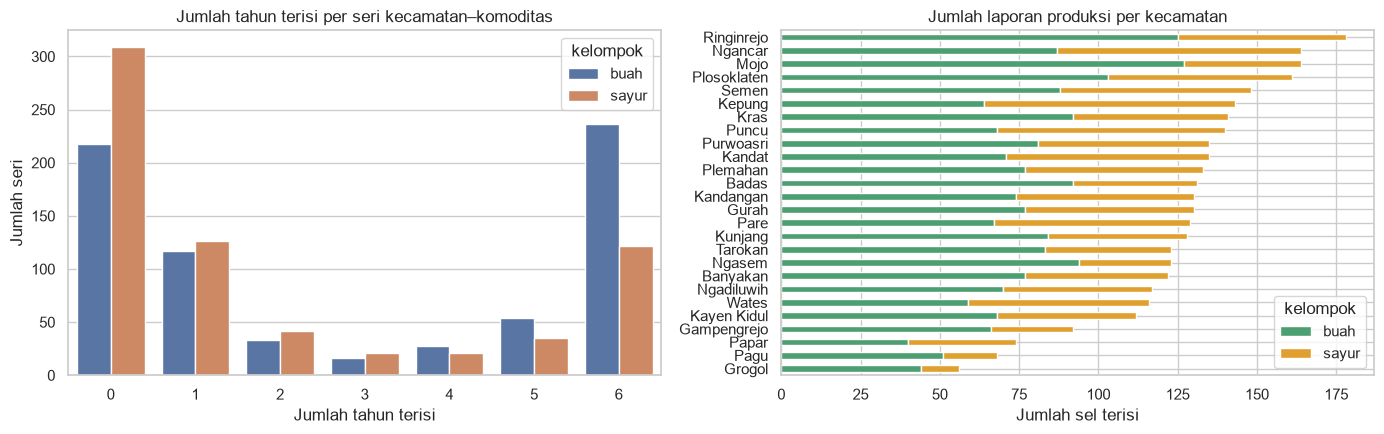

In [10]:
n_tahun = (clean[clean["tahun"].isin(COMPLETE_YEARS)].groupby(["kelompok", "kecamatan", "komoditas"])["produksi"].count()
           .rename("n_tahun_terisi").reset_index())
display(n_tahun.groupby(["kelompok", "n_tahun_terisi"]).size().unstack("kelompok").fillna(0).astype(int).T)
print("Seri lengkap:", (n_tahun["n_tahun_terisi"] == len(COMPLETE_YEARS)).sum(), "dari", len(n_tahun))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(data=n_tahun, x="n_tahun_terisi", hue="kelompok", ax=ax[0])
ax[0].set_title("Jumlah tahun terisi per seri kecamatan–komoditas"); ax[0].set_xlabel("Jumlah tahun terisi"); ax[0].set_ylabel("Jumlah seri")
mk = clean[clean["tahun"].isin(COMPLETE_YEARS)].pivot_table(index="kecamatan", columns="kelompok", values="produksi", aggfunc="count")
mk = mk.reindex(mk.sum(axis=1).sort_values().index)
mk.plot.barh(stacked=True, ax=ax[1], color=["#4c9f70", "#e0a030"]); ax[1].set_title("Jumlah laporan produksi per kecamatan"); ax[1].set_xlabel("Jumlah sel terisi"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

komoditas dominan

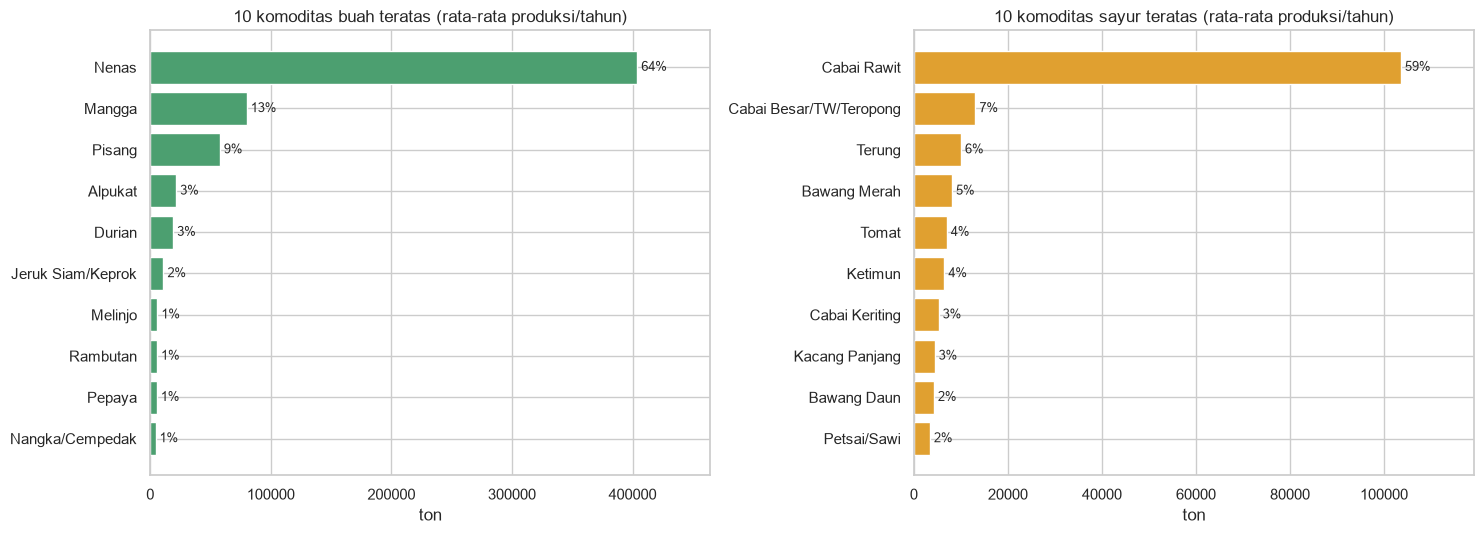

5 komoditas teratas (% produksi kelompok): {'buah': 91.8, 'sayur': 81.0}


In [11]:
kab_c = kab[kab["tahun"].isin(COMPLETE_YEARS)]
dom = kab_c.groupby(["kelompok", "komoditas"])["produksi"].mean().div(TON).rename("produksi_ton").reset_index()
dom["porsi_kelompok_%"] = 100 * dom["produksi_ton"] / dom.groupby("kelompok")["produksi_ton"].transform("sum")
dom = dom.sort_values(["kelompok", "produksi_ton"], ascending=[True, False])
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, kel, col in zip(ax, ["buah", "sayur"], ["#4c9f70", "#e0a030"]):
    g = dom[dom["kelompok"] == kel].head(10).iloc[::-1]
    a.barh(g["komoditas"], g["produksi_ton"], color=col)
    for y_, (v, p) in enumerate(zip(g["produksi_ton"], g["porsi_kelompok_%"])): a.text(v, y_, f" {p:.0f}%", va="center", fontsize=9)
    a.set_title(f"10 komoditas {kel} teratas (rata-rata produksi/tahun)"); a.set_xlabel("ton"); a.set_xlim(0, g["produksi_ton"].max() * 1.15)
plt.tight_layout(); plt.show()
print("5 komoditas teratas (% produksi kelompok):", dom.groupby("kelompok").head(5).groupby("kelompok")["porsi_kelompok_%"].sum().round(1).to_dict())

tren produksi

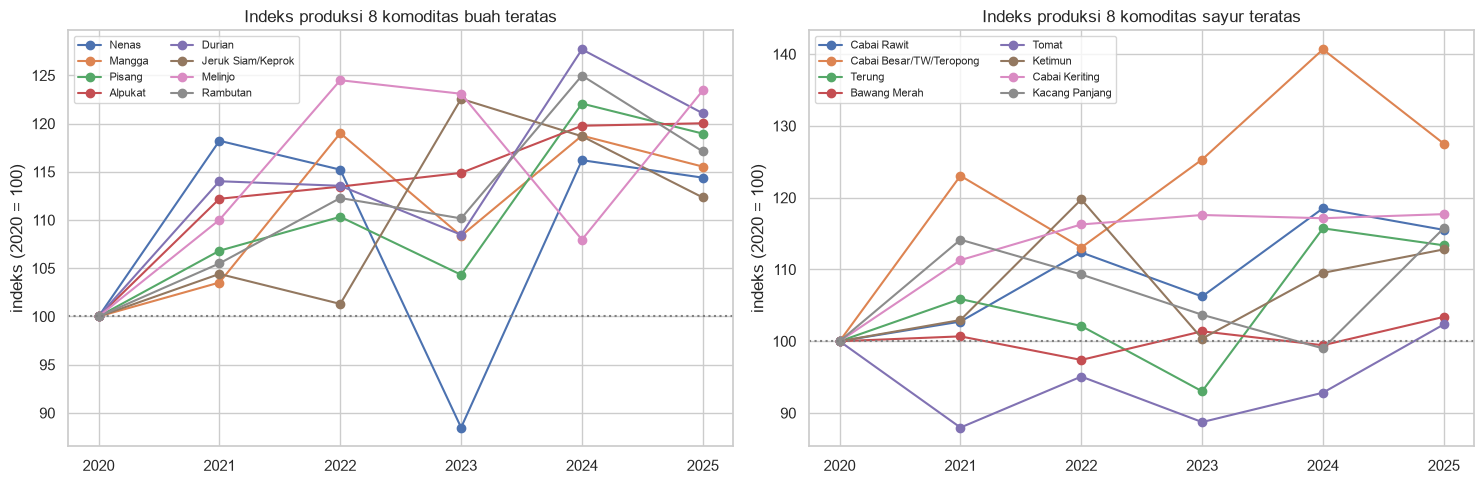

Total produksi kabupaten (ton):


kelompok,buah,sayur
tahun,,
2020,579614.0,161931.0
2021,660253.0,168438.0
2022,663679.0,178421.0
2023,555057.0,170687.0
2024,680157.0,186423.0
2025,668577.0,183733.0


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, kel in zip(ax, ["buah", "sayur"]):
    top = dom[dom["kelompok"] == kel].head(8)["komoditas"]
    p = kab[(kab["kelompok"] == kel) & kab["komoditas"].isin(top)].pivot(index="tahun", columns="komoditas", values="produksi")[list(top)]
    idx = 100 * p / p.iloc[0]
    idx.plot(marker="o", ax=a); a.axhline(100, c="gray", ls=":")
    a.set_title(f"Indeks produksi 8 komoditas {kel} teratas"); a.set_ylabel(f"indeks ({int(p.index[0])} = 100)"); a.set_xlabel(""); a.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
print("Total produksi kabupaten (ton):"); display(kab.groupby(["kelompok", "tahun"])["produksi"].sum().div(TON).unstack("kelompok").round(0))

produktivitas dan nilai ekstrem

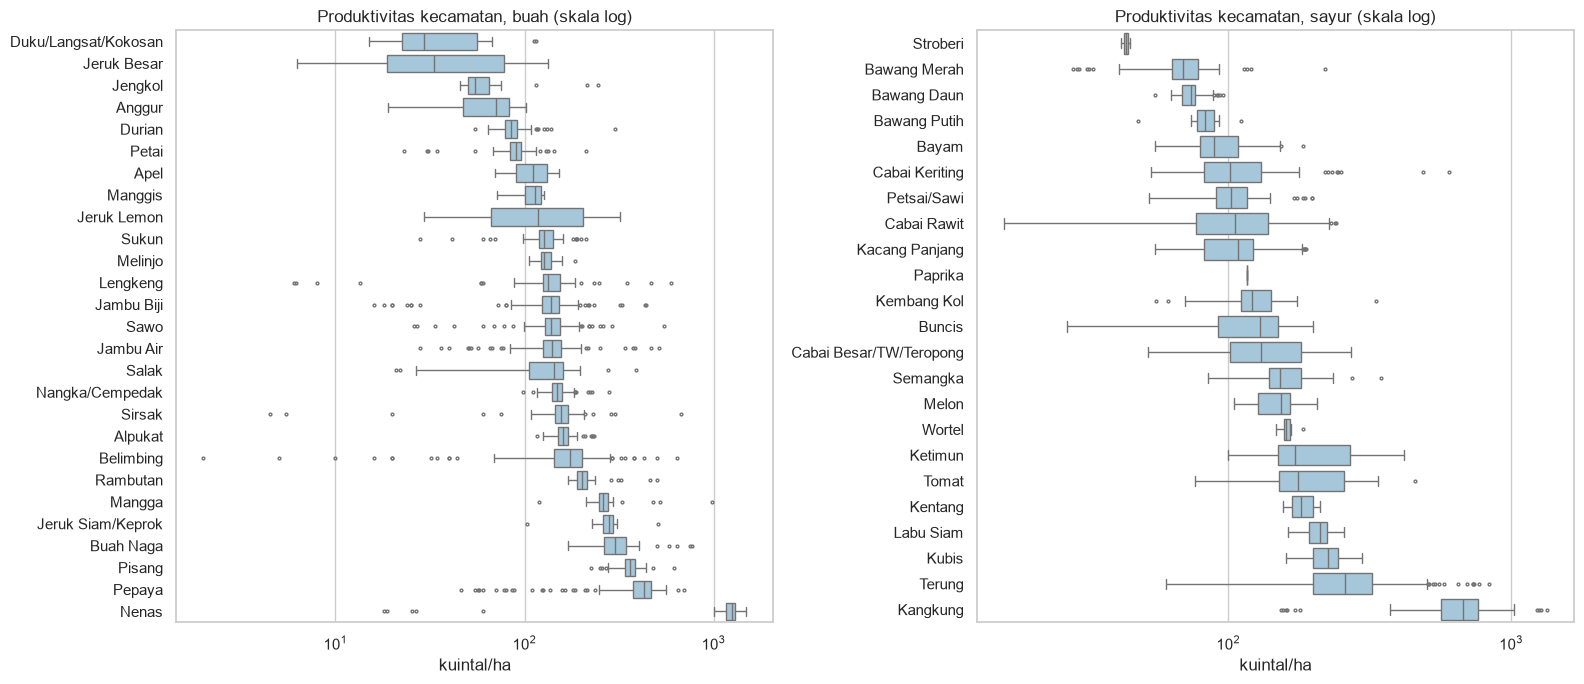

Produktivitas ekstrem (3xIQR pada log): 134 dari 3214 baris (4.2%)


,kelompok,kecamatan,komoditas,tahun,luas,kw_per_ha,median_komoditas
1221,buah,Kayen Kidul,Mangga,2023,0.2,984.0,502.0
2418,buah,Ngasem,Sirsak,2020,0.2,670.0,67.6
3261,buah,Puncu,Belimbing,2023,0.2,640.0,26.0
3857,buah,Semen,Pisang,2025,0.5,620.0,422.6
6123,sayur,Ngadiluwih,Cabai Keriting,2023,0.2,604.0,604.0
2995,buah,Plemahan,Lengkeng,2021,0.2,596.0,58.8
4033,buah,Tarokan,Sawo,2021,0.2,548.0,51.3
3488,buah,Purwoasri,Mangga,2022,0.2,524.0,502.0
1503,buah,Kras,Jambu Air,2023,0.2,512.0,54.5
1372,buah,Kepung,Jeruk Siam/Keprok,2024,0.2,511.0,307.0


In [15]:
pr = clean[(clean["unit_luas"] == "ha") & clean["produktivitas"].notna()].copy()
pr["kw_per_ha"] = pr["produktivitas"] / 100
urut = pr.groupby("komoditas")["kw_per_ha"].median().sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, kel in zip(ax, ["buah", "sayur"]):
    g = pr[pr["kelompok"] == kel]; o = [k for k in urut if k in set(g["komoditas"])]
    sns.boxplot(data=g, y="komoditas", x="kw_per_ha", order=o, ax=a, fliersize=2, color="#9ecae1"); a.set_xscale("log")
    a.set_title(f"Produktivitas kecamatan, {kel} (skala log)"); a.set_xlabel("kuintal/ha"); a.set_ylabel("")
plt.tight_layout(); plt.show()

lg = np.log(pr["kw_per_ha"]); q1, q3 = lg.groupby(pr["komoditas"]).transform(lambda s: s.quantile(.25)), lg.groupby(pr["komoditas"]).transform(lambda s: s.quantile(.75))
pr["ekstrem"] = (lg < q1 - 3 * (q3 - q1)) | (lg > q3 + 3 * (q3 - q1))
print(f"Produktivitas ekstrem (3xIQR pada log): {pr['ekstrem'].sum()} dari {len(pr)} baris ({100 * pr['ekstrem'].mean():.1f}%)")
display(pr[pr["ekstrem"]].assign(median_komoditas=lambda d: d.groupby("komoditas")["kw_per_ha"].transform("median"))
        [["kelompok", "kecamatan", "komoditas", "tahun", "luas", "kw_per_ha", "median_komoditas"]].sort_values("kw_per_ha", ascending=False).head(12).round(1))
pr[pr["ekstrem"]].to_csv(DIRS["reports"] / "produktivitas_ekstrem_hortikultura.csv", index=False)

luas vs produksi dan kontribusi kecamatan

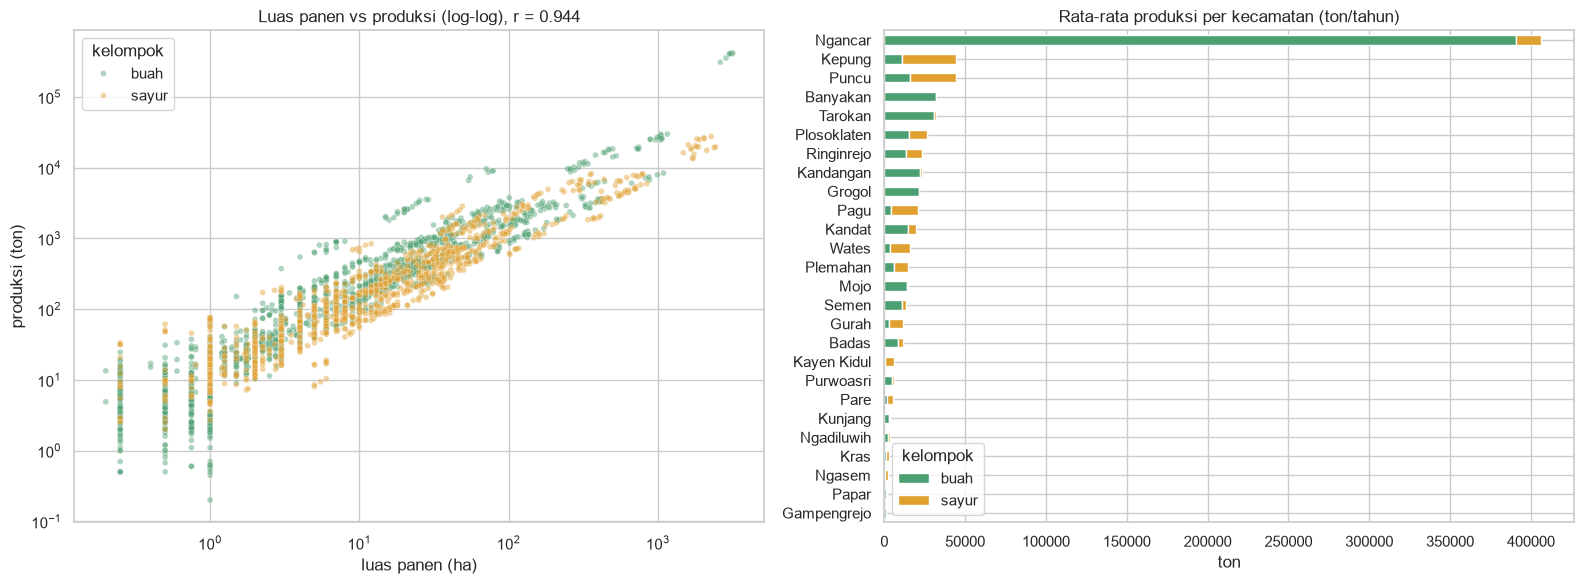

Porsi 5 kecamatan teratas: {'Ngancar': 50.2, 'Kepung': 5.5, 'Puncu': 5.5, 'Banyakan': 4.0, 'Tarokan': 3.9} | jumlah: 69.1 %


In [16]:
sc = clean[(clean["unit_luas"] == "ha")].dropna(subset=["produksi", "luas"])
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=sc, x="luas", y=sc["produksi"] / TON, hue="kelompok", alpha=.45, s=18, ax=ax[0], palette=["#4c9f70", "#e0a030"])
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("luas panen (ha)"); ax[0].set_ylabel("produksi (ton)")
r = np.corrcoef(np.log(sc["luas"]), np.log(sc["produksi"]))[0, 1]; ax[0].set_title(f"Luas panen vs produksi (log-log), r = {r:.3f}")

kc = clean[clean["tahun"].isin(COMPLETE_YEARS)].groupby(["kecamatan", "kelompok"])["produksi"].sum().div(len(COMPLETE_YEARS) * TON).unstack("kelompok").fillna(0)
kc = kc.loc[kc.sum(axis=1).sort_values().index]
kc.plot.barh(stacked=True, ax=ax[1], color=["#4c9f70", "#e0a030"]); ax[1].set_title("Rata-rata produksi per kecamatan (ton/tahun)"); ax[1].set_xlabel("ton"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()
sh = (kc.sum(axis=1) / kc.sum().sum() * 100).sort_values(ascending=False)
print("Porsi 5 kecamatan teratas:", sh.head(5).round(1).to_dict(), "| jumlah:", round(sh.head(5).sum(), 1), "%")

gejolak antartahun

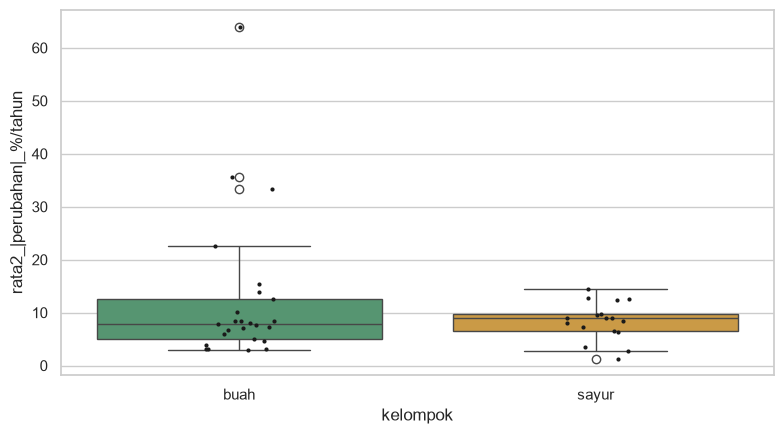

Median perubahan absolut tahunan (%): {'buah': 7.9, 'sayur': 9.0} | seri: 42


In [18]:
pv = kab_c.pivot_table(index=["kelompok", "komoditas"], columns="tahun", values="produksi")
pv = pv[(pv.notna().all(axis=1)) & (pv > 0).all(axis=1)]
yoy = 100 * pv.pct_change(axis=1).iloc[:, 1:].abs()
vol = yoy.mean(axis=1).rename("rata2_|perubahan|_%/tahun").reset_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=vol, x="kelompok", y="rata2_|perubahan|_%/tahun", ax=ax, palette=["#4c9f70", "#e0a030"]); sns.stripplot(data=vol, x="kelompok", y="rata2_|perubahan|_%/tahun", color="k", size=3, ax=ax)
plt.tight_layout(); plt.show()
print("Median perubahan absolut tahunan (%):", vol.groupby("kelompok")["rata2_|perubahan|_%/tahun"].median().round(1).to_dict(), "| seri:", len(vol))